# Assignment 1: Model Forensics – Task 1
## Initial Inspection & Hypothesis Formation
**Author:** Harshavardini Gowrisankar

---

### Objective
Evaluate the pre-trained ResNet-18 classifier (`waterbirds_erm_resnet18_biased.pt`) on the 5 customer example images, record predictions and softmax confidence scores against the ground-truth species labels, identify systematic failure patterns, and formulate falsifiable hypotheses for forensic testing.

> **Read-Only Shared Files Rule:** `Start.py`, `waterbirds_model.py`, `waterbirds_erm_resnet18_biased.pt`, and `data/customer_examples/` are imported directly without modification.

In [1]:
from pathlib import Path
import torch
from torchvision import transforms
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# Import from read-only starter module
from waterbirds_model import load_model, CLASS_NAMES

# Standard ResNet-18 ImageNet preprocessing
PREPROCESS = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

# Ground-truth biological class, species name, and observed background
GROUND_TRUTH = {
    "Cape_May_Warbler_0048_162915.jpg": ("landbird", "Cape May Warbler", "land"),
    "Common_Tern_0067_149540.jpg": ("waterbird", "Common Tern", "water"),
    "Slaty_Backed_Gull_0079_796020.jpg": ("waterbird", "Slaty-backed Gull", "land"),
    "Sooty_Albatross_0036_796387.jpg": ("waterbird", "Sooty Albatross", "land"),
    "White_Pelican_0076_96427.jpg": ("waterbird", "White Pelican", "water"),
}

base_dir = Path.cwd()
checkpoint_path = base_dir / "waterbirds_erm_resnet18_biased.pt"
images_dir = base_dir / "data" / "customer_examples"
results_dir = base_dir / "results"
results_dir.mkdir(parents=True, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = load_model(str(checkpoint_path), device)
print(f"Loaded model on {device}. Class mapping: {CLASS_NAMES}")

Loaded model on cuda. Class mapping: {0: 'landbird', 1: 'waterbird'}


In [2]:
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
image_paths = sorted(
    p for p in images_dir.iterdir()
    if p.is_file() and p.suffix.lower() in valid_exts
)

records = []
loaded_images = []

with torch.no_grad():
    for img_path in image_paths:
        pil_img = Image.open(img_path).convert("RGB")
        loaded_images.append((img_path.name, pil_img))

        input_tensor = PREPROCESS(pil_img).unsqueeze(0).to(device)
        logits = model(input_tensor)
        probs = torch.softmax(logits, dim=1).squeeze(0).cpu()

        pred_idx = int(torch.argmax(probs).item())
        pred_label = CLASS_NAMES[pred_idx]
        prob_landbird = float(probs[0].item())
        prob_waterbird = float(probs[1].item())
        confidence = float(probs[pred_idx].item())

        gt_bird, species, gt_bg = GROUND_TRUTH[img_path.name]
        is_correct = pred_label == gt_bird

        records.append({
            "filename": img_path.name,
            "species": species,
            "ground_truth_bird": gt_bird,
            "ground_truth_background": gt_bg,
            "predicted_class": pred_label,
            "confidence": round(confidence, 4),
            "prob_landbird": round(prob_landbird, 4),
            "prob_waterbird": round(prob_waterbird, 4),
            "correct": is_correct,
        })

df_results = pd.DataFrame(records)
csv_path = results_dir / "task1_predictions.csv"
df_results.to_csv(csv_path, index=False)

overall_acc = df_results["correct"].mean() * 100
waterbird_acc = df_results[df_results["ground_truth_bird"] == "waterbird"]["correct"].mean() * 100
print(f"Overall Accuracy: {overall_acc:.1f}% ({df_results['correct'].sum()}/{len(df_results)})")
print(f"Waterbird Accuracy: {waterbird_acc:.1f}% (2/4)")

df_results

Overall Accuracy: 60.0% (3/5)
Waterbird Accuracy: 50.0% (2/4)


,filename,species,ground_truth_bird,ground_truth_background,predicted_class,confidence,prob_landbird,prob_waterbird,correct
0,Cape_May_Warbler_0048_162915.jpg,Cape May Warbler,landbird,land,landbird,1.0000,1.0000,0.0000,True
1,Common_Tern_0067_149540.jpg,Common Tern,waterbird,water,waterbird,1.0000,0.0000,1.0000,True
2,Slaty_Backed_Gull_0079_796020.jpg,Slaty-backed Gull,waterbird,land,landbird,0.9564,0.9564,0.0436,False
3,Sooty_Albatross_0036_796387.jpg,Sooty Albatross,waterbird,land,landbird,0.9536,0.9536,0.0464,False
4,White_Pelican_0076_96427.jpg,White Pelican,waterbird,water,waterbird,1.0000,0.0000,1.0000,True


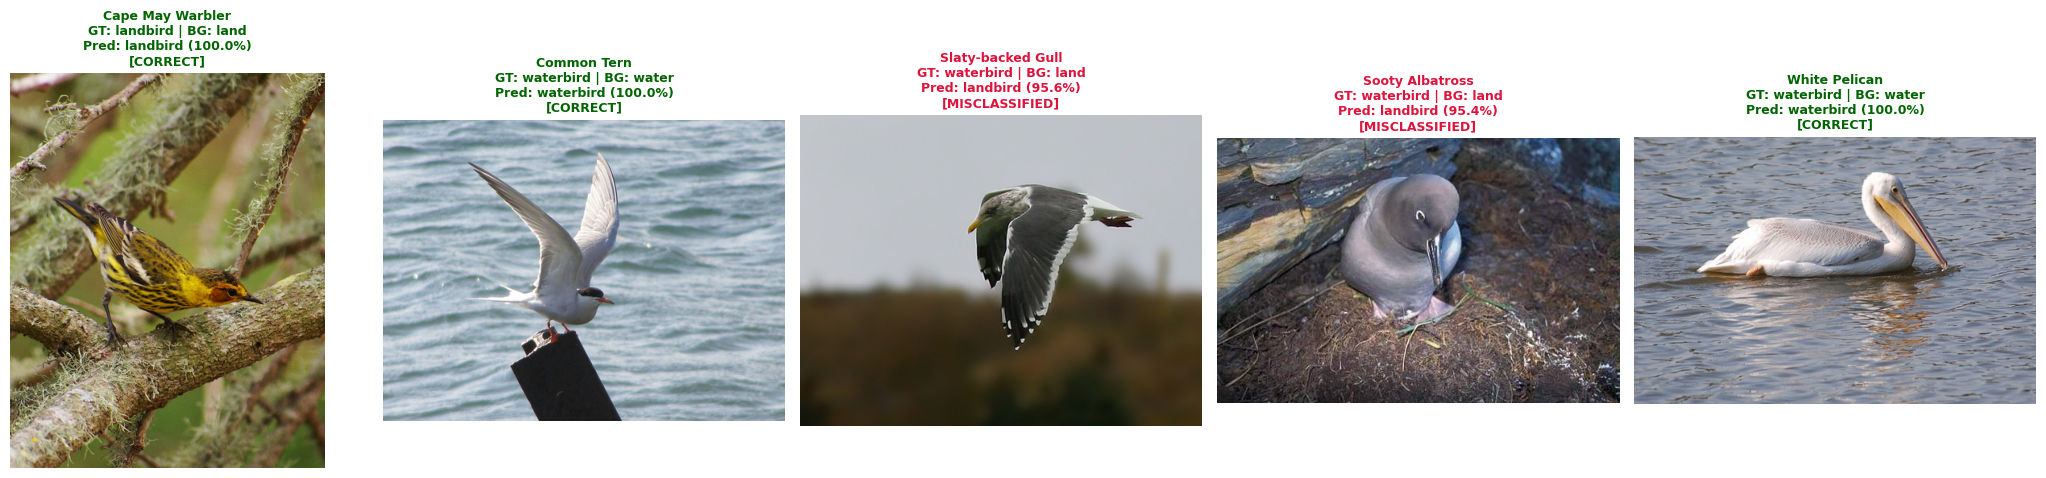

Saved inspection grid to: d:\CV\CV-Forensics-Edge\Assignment-1-Model_Forensics\results\task1_inspection_grid.png


In [3]:
fig, axes = plt.subplots(1, len(loaded_images), figsize=(4.2 * len(loaded_images), 4.8))
if len(loaded_images) == 1:
    axes = [axes]

for idx, ((fname, pil_img), row) in enumerate(zip(loaded_images, records)):
    axes[idx].imshow(pil_img)
    axes[idx].axis("off")
    status = "CORRECT" if row["correct"] else "MISCLASSIFIED"
    title_color = "darkgreen" if row["correct"] else "crimson"

    title_text = (
        f"{row['species']}\n"
        f"GT: {row['ground_truth_bird']} | BG: {row['ground_truth_background']}\n"
        f"Pred: {row['predicted_class']} ({row['confidence'] * 100:.1f}%)\n"
        f"[{status}]"
    )
    axes[idx].set_title(title_text, fontsize=9, color=title_color, fontweight="bold")

grid_path = results_dir / "task1_inspection_grid.png"
plt.tight_layout()
plt.savefig(grid_path, dpi=200, bbox_inches="tight")
plt.show()
print(f"Saved inspection grid to: {grid_path}")

## Pattern Analysis & Formulated Hypotheses

### 1. Summary of Empirical Findings
* **Overall Customer Accuracy:** **60.0% (3/5)**; **Waterbird Accuracy:** **50.0% (2/4)**.
* **Background-Aligned Samples (100% Accuracy — 3/3):**
  * `Cape_May_Warbler_0048_162915.jpg` (*landbird* on *land*) $\rightarrow$ predicted `landbird` (**100.0%** confidence).
  * `Common_Tern_0067_149540.jpg` (*waterbird* on *water*) $\rightarrow$ predicted `waterbird` (**100.0%** confidence).
  * `White_Pelican_0076_96427.jpg` (*waterbird* on *water*) $\rightarrow$ predicted `waterbird` (**100.0%** confidence).
* **Background-Shifted Samples (0% Accuracy — 0/2):**
  * `Slaty_Backed_Gull_0079_796020.jpg` (*waterbird* flying over *grass/land*) $\rightarrow$ misclassified as `landbird` (**95.6%** confidence).
  * `Sooty_Albatross_0036_796387.jpg` (*waterbird* on *rocky nest/land*) $\rightarrow$ misclassified as `landbird` (**95.4%** confidence).

### 2. Observed Visual Pattern
Across all 5 images, the model's prediction aligns **100% with the background habitat** (`water` $\rightarrow$ `waterbird`, `foliage/grass/rock` $\rightarrow$ `landbird`) rather than the bird's morphological features, exhibiting extreme overconfidence (>95%) even when wrong.

### 3. Formulated Hypotheses
* **Hypothesis 1 (Spurious Background Shortcut):** The ResNet-18 classifier predicts the class based on **background habitat cues** (water textures $\rightarrow$ `waterbird`; foliage, grass, or rock $\rightarrow$ `landbird`) rather than morphological bird features (beak, wings, plumage), causing waterbirds photographed on land to be misclassified with >95% confidence.

* **Hypothesis 2 (Internal Evaluation Distribution Bias):** The model achieved **99% accuracy on waterbirds** and **98% accuracy on landbirds** during internal evaluation because the internal dataset consisted predominantly of canonical background-aligned pairs (*waterbirds on water*, *landbirds on land*), masking the model's failure on out-of-distribution backgrounds.